In [1]:
from BLEanalysis.signals import Signals
from BLEanalysis.angleinference import AnglesUsePeaks, AnglesUseRejectionSampling, AnglesUsePatternMeans, normalise_logs_to_ps
import numpy as np
import matplotlib.pyplot as plt
import matplotlib as mpl
import pyproj
from jax.random import normal
import jax
import jax.numpy as jnp
from jax.random import multivariate_normal as mvn
from scipy.stats import circmean
from jax.scipy.stats import norm
from jax import grad
import pickle
font = {'family' : 'sans-serif',
        'weight' : 'normal',
        'size'   : 15}

mpl.rc('font', **font)
import numpy as np

/opt/anaconda3/envs/newEnv/lib/python3.12/site-packages/pyproj/network.py:59: UserWarning: pyproj unable to set PROJ database path.
  _set_context_ca_bundle_path(ca_bundle_path)


In [2]:
def likelihood(predictedX, predictedY, transmitterX, transmitterY, vectorX, vectorY, obsNoise):
    distanceX = predictedX - transmitterX
    distanceY = predictedY - transmitterY
    cross = vectorX * distanceY - vectorY * distanceX
    return -jnp.sum(jax.scipy.stats.norm.logpdf(cross, 0, obsNoise))


def run(times, observations, nParticles=50000,
        posNoise=1.0, velNoise=0.5,
        sigmaMean=5.0, sigmaStd=2.0,
        sigmaJitter=0.05,
        lr=0.5, steps=10):

    key = jax.random.PRNGKey(12345)

    # Particles consist of [position X, position Y, velocity X, velocity Y, noise]
    particles = jnp.zeros((nParticles, 5))
    key, keyX, keyY = jax.random.split(key, 3)
    particles = particles.at[:, 0].set(jax.random.normal(keyX, (nParticles,)) * 100)
    particles = particles.at[:, 1].set(jax.random.normal(keyY, (nParticles,)) * 100)

    # Each particle has its own guess at the observation noise (Liu & West (2001))
    # allowing the model to guess at the observation noise via the resampling process.
    key, keySigma = jax.random.split(key)
    sigmaSamples = jnp.abs(sigmaMean + sigmaStd * jax.random.normal(keySigma, (nParticles,)))
    particles = particles.at[:, 4].set(jnp.log(sigmaSamples))

    # Init weights for resampling
    weights = jnp.full(nParticles, 1 / nParticles)

    path = []
    previousTime = times[0]  # Start at time = 0

    # For each observation sequentially (obs MUST be ordered in time)
    for step, (time, (transmitterX, transmitterY, vectorX, vectorY)) in enumerate(zip(times, observations)):
        deltaTime = time - previousTime
        deltaTime = jnp.maximum(deltaTime, 1e-6)  # If two times are the same?
        previousTime = time

        key, keyVX, keyVY, keyPX, keyPY, keyJitter, keyResample = jax.random.split(key, 7)

        # Nudge every particle's velocity by some ammount that scales with time between obs
        # (see discretized nearly-constant-velocity models)
        particles = particles.at[:, 2].add(jax.random.normal(keyVX, (nParticles,)) * velNoise * jnp.sqrt(deltaTime))
        particles = particles.at[:, 3].add(jax.random.normal(keyVY, (nParticles,)) * velNoise * jnp.sqrt(deltaTime))
        # Now update the particle's position by moving it in the direction of its velocity
        # for the amount of time between this observation and the previous
        particles = particles.at[:, 0].add(particles[:, 2] * deltaTime
                                           + jax.random.normal(keyPX, (nParticles,)) * posNoise * jnp.sqrt(deltaTime))
        particles = particles.at[:, 1].add(particles[:, 3] * deltaTime
                                           + jax.random.normal(keyPY, (nParticles,)) * posNoise * jnp.sqrt(deltaTime))

        # Also nudge each particle's observation noise guess by some random ammount
        particles = particles.at[:, 4].add(jax.random.normal(keyJitter, (nParticles,)) * sigmaJitter)

        # Use gradient ascent to optimise particles (I don't think this is useful I just wanted to try it :D,
        # maybe if the time deltas are bigger it'll be more handy since the particles will spread so far out
        # between states that barely any will be close to the true location/survive resampling in a useful way)
        particlePositionsX = particles[:, 0]
        particlePositionsY = particles[:, 1]
        sigma = jnp.exp(particles[:, 4])
        for _ in range(steps):
            # X and Y optimised separately, could do it together?
            gradX, gradY = grad(likelihood, [0, 1])(particlePositionsX, particlePositionsY,
                                                    transmitterX, transmitterY, vectorX,
                                                    vectorY, sigma)
            particlePositionsX = particlePositionsX + lr * gradX
            particlePositionsY = particlePositionsY + lr * gradY
        particles = particles.at[:, 0].set(particlePositionsX)
        particles = particles.at[:, 1].set(particlePositionsY)

        # Use same likelihood to weight each particle
        distX = particles[:, 0] - transmitterX
        distY = particles[:, 1] - transmitterY
        cross = jnp.abs(vectorX * distY - vectorY * distX)
        weights = jnp.exp(jax.scipy.stats.norm.logpdf(cross, 0, jnp.exp(particles[:, 4])))
        weights /= weights.sum()  # Must add up to 1

        # Resample particles by weights
        idx = jax.random.choice(keyResample, nParticles, shape=(nParticles,), p=weights)
        particles = particles[idx]
        weights = jnp.full(nParticles, 1 / nParticles)

        # Update path with current state
        path.append(particles[:, :2].mean(axis=0))

    return jnp.stack(path)

def runBackward(times, observations):
    # Reverse the observations and timestamps to run the filter in reverse
    times = jnp.asarray(times)
    observations = jnp.asarray(observations)
    timesReversed = times[::-1]
    timesReversed = timesReversed[0] - timesReversed  # now starts at 0 and increases
    observationsReversed = observations[::-1]

    result = run(timesReversed, observationsReversed)

    # Put them back into the correct order so the start is in the right place again
    return jnp.asarray(result)[::-1]

Standardising angles and times (shifting by 0.00 degrees)
Transmitter       Number of records
        a                 4754
        b                 6160
        c                12619
        e                 2759


/opt/anaconda3/envs/newEnv/lib/python3.12/site-packages/numpy/core/_methods.py:206: RuntimeWarning: Degrees of freedom <= 0 for slice
  ret = _var(a, axis=axis, dtype=dtype, out=out, ddof=ddof,
/opt/anaconda3/envs/newEnv/lib/python3.12/site-packages/numpy/core/_methods.py:163: RuntimeWarning: invalid value encountered in divide
  arrmean = um.true_divide(arrmean, div, out=arrmean,
/opt/anaconda3/envs/newEnv/lib/python3.12/site-packages/numpy/core/_methods.py:198: RuntimeWarning: invalid value encountered in scalar divide
  ret = ret.dtype.type(ret / rcount)


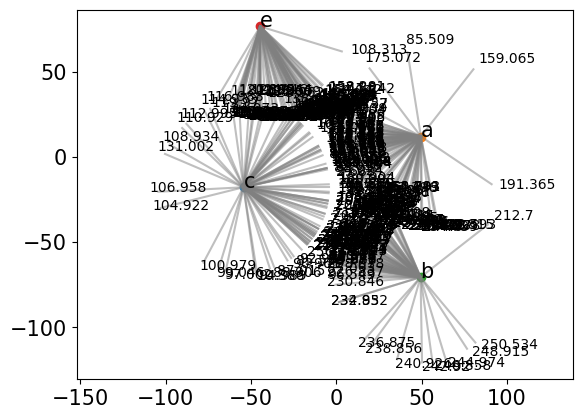

In [11]:
# Load data and process, copied from other path inference stuff

pathIndex = 0
nSamps = 20 # Max number of samples to use per burst for path reconstruction
             # (2 second bursts, how many samples within that burst)
paths = [["../bluetooth_experiments/March 26 2025 Field Trial/complexpath7/complexpath7.log", "../bluetooth_experiments/March 26 2025 Field Trial/complexpath7/2025-03-26_12_05_30_my_iOS_device.csv", 8,26],
         ["../bluetooth_experiments/March 26 2025 Field Trial/complexpath8/complexpath8.log","../bluetooth_experiments/March 26 2025 Field Trial/complexpath8/2025-03-26_12_09_13_my_iOS_device.csv",7,24],
         ["../bluetooth_experiments/March 26 2025 Field Trial/complexpath9/complexpath9.log","../bluetooth_experiments/March 26 2025 Field Trial/complexpath9/2025-03-26_12_13_54_my_iOS_device.csv" ,5,28],
         ["../bluetooth_experiments/March 26 2025 Field Trial/complexpath10/complexpath10.log","../bluetooth_experiments/March 26 2025 Field Trial/complexpath10/2025-03-26_12_19_59_my_iOS_device.csv" ,14,37],
         ["../bluetooth_experiments/March 26 2025 Field Trial/complexpath11/complexpath11.log","../bluetooth_experiments/March 26 2025 Field Trial/complexpath11/2025-03-26_12_25_20_my_iOS_device.csv" ,4,27],
         ["../bluetooth_experiments/March 26 2025 Field Trial/straightpath3/straightpath3.log","../bluetooth_experiments/March 26 2025 Field Trial/straightpath3/2025-03-26_11_42_42_my_iOS_device.csv" ,6,21]]

testdata = Signals(paths[pathIndex][0],['c','a','b','e'],filetype='log',angleOffset=0)
GPSfilepath = paths[pathIndex][1]

# For evaluating the GPS path pointwise against the inferred path, we want to infer a path across the times that we've tracked with GPS
startingTime = paths[pathIndex][2]
endingTime = paths[pathIndex][3]

testdata.configureTransmitter('c',0,np.deg2rad(15),transmitterLat = 53.368359, transmitterLon = -1.450168)
testdata.configureTransmitter('a',-(167340+194210),0,transmitterLat = 53.368606, transmitterLon = -1.448596)
testdata.configureTransmitter('b',-(167340+194210+121110),-np.deg2rad(15),transmitterLat = 53.367865, transmitterLon = -1.448626)
testdata.configureTransmitter('e',-167340,0,transmitterLat = 53.369204, transmitterLon = -1.449990)
# Normalise the transmitter locations around zero, in preparation for the observations
testdata.noramliseTransmitterLocs()
normFactor = testdata.coordNormalisationFactor
testdata.summarise(showNormalised = True)

obs = []
obstimes = []

# Get packet bursts from data
burst, time = testdata.parseBursts(burstInterval=0)
angles = AnglesUsePeaks(windowLength=3)

# For each burst
for b in range(len(burst)):
    # Infer an angle
    burst[b] = testdata.subsampleBurst(burst[b], nSamps, 2000, method="linspaceIdxs")
    prediction = angles.infer(burst[b]['rssis'], burst[b]['angles'])
    # If a peak was found
    if not (np.isnan(prediction)):
        # Add observation in form [transmitter_x, transmitter_y, vector_x, vector_y]
        obs.append([burst[b]['transmitter_position'][0][1], burst[b]['transmitter_position'][0][0], np.sin(prediction), np.cos(prediction)])
        # Add time of observation
        obstimes.append(time[b])

# Scale down times and standardise times such that they start at zero
time_min = np.min(obstimes)
for i in range(len(obstimes)):
    obstimes[i] = (obstimes[i] - time_min) /1000

plt.axis('equal')
for (observation, time) in zip(obs, obstimes):
    plt.plot([observation[0], observation[0]+observation[2]*50],[observation[1],observation[1]+observation[3]*50],color='grey',alpha=0.5)
    plt.text(observation[0]+observation[2]*55, observation[1]+observation[3]*55, time, size=10)

obs = np.array(obs)
obstimes = np.array(obstimes)

# Obs have to be sorted
order = np.argsort(obstimes)
obstimes = obstimes[order]
obs = obs[order]

(-76.51832790374756, 63.903761100769046, -97.82445167466066, 40.54401126313023)

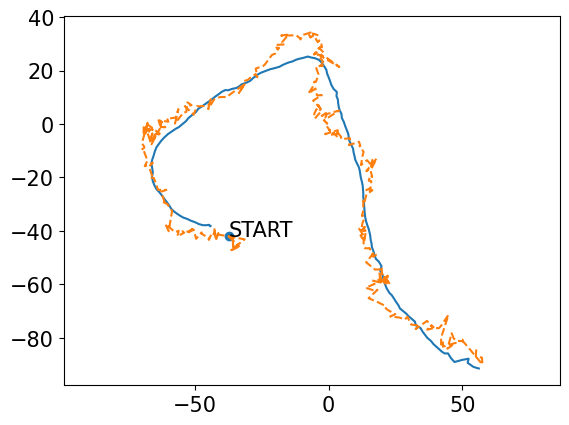

In [12]:
pathForward = run(obstimes, obs)
pathBackward = runBackward(obstimes, obs)

# Average forward and backward passes
path = (pathForward + pathBackward) / 2

P = pyproj.Proj(proj='utm', zone=30, ellps='WGS84', preserve_units=True)
GPSFile = paths[pathIndex][1]
# plot gps use number of GPS readings as inference points
with open(GPSFile, 'r') as f:
    filedata = f.read()
    GPSData = filedata[299:].split('\n')
    n_test = len(GPSData)
    
    lat = []
    lon = []
    for coord in GPSData[:-1]:
        coord = coord.split(',')
        lat.append(float(coord[3]))
        lon.append(float(coord[4]))
    GPSxx, GPSyy = P(lon,lat)
plt.plot(np.array(GPSxx)- normFactor[1], np.array(GPSyy)-normFactor[0], label="GNSS Ground Truth")
plt.plot(path[10:len(path)-10, 0], path[10:len(path)-10, 1], "--", label="estimate")
plt.text(path[10,0], path[10,1], "START")
plt.scatter(path[10,0], path[10,1])
#plt.legend()
plt.axis("equal")
#testdata.summarise(showNormalised = False)